d:\anaconda3\envs\pytorch1_12_1\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\CPC-ML\AppData\Local\Temp\ipykernel_23816\1946260029.py:40: UserWarning: __floordiv__ is deprecated, and its behavior will change in a future version of pytorch. It currently rounds toward 0 (like the 'trunc' function NOT 'floor'). This results in incorrect rounding for negative values. To keep the current behavior, use torch.div(a, b, rounding_mode='trunc'), or for actual floor division, use torch.div(a, b, rounding_mode='floor').
  i = (idx // 4) * 2 - 3


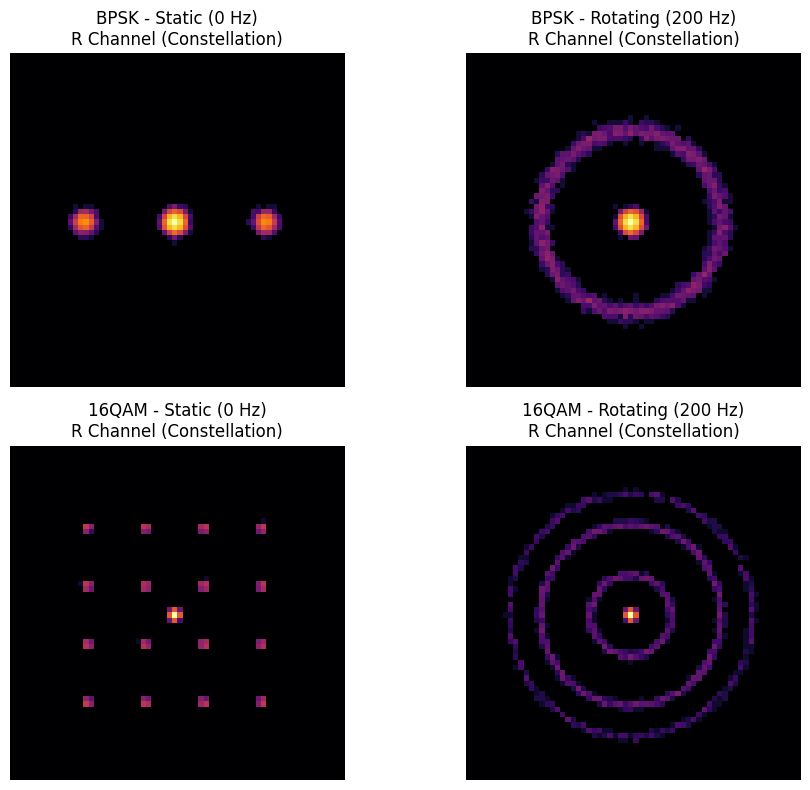

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

# ================= 核心工具 (复用你的代码逻辑) =================
def fast_hist2d(x, y, bins=64, range_bounds=((-1.2, 1.2), (-1.2, 1.2))):
    x_min, x_max = range_bounds[0]
    y_min, y_max = range_bounds[1]
    x = torch.clamp(x, x_min, x_max)
    y = torch.clamp(y, y_min, y_max)
    x_idx = ((x - x_min) / (x_max - x_min) * (bins - 1)).long()
    y_idx = ((y - y_min) / (y_max - y_min) * (bins - 1)).long()
    flat_idx = y_idx * bins + x_idx
    hist = torch.bincount(flat_idx, minlength=bins*bins)
    return hist.view(bins, bins).float()

def generate_r_channel_only(sig, img_size=64):
    """只生成 R 通道 (星座图) 用于观察旋转"""
    scale = torch.sqrt(torch.mean(sig.real**2 + sig.imag**2)) + 1e-9
    norm_iq = sig / (3.0 * scale)
    hist_r = fast_hist2d(norm_iq.real, norm_iq.imag, bins=img_size)
    hist_r = torch.log1p(hist_r)
    hist_r = (hist_r - hist_r.min()) / (hist_r.max() - hist_r.min() + 1e-8)
    return torch.flip(hist_r, [0])

def generate_signal(mod_type, freq_offset_hz):
    """生成带指定频偏的信号"""
    N = 10240
    Fs, Rs = 80e3, 20e3
    sps = 4
    num_symbols = N // sps + 50
    t = torch.arange(N, dtype=torch.float32) / Fs

    # 1. 生成符号
    if mod_type == "BPSK":
        syms = 2*torch.randint(0, 2, (num_symbols,)) - 1 + 0j
    elif mod_type == "16QAM":
        idx = torch.randint(0, 16, (num_symbols,))
        i = (idx // 4) * 2 - 3
        q = (idx % 4) * 2 - 3
        syms = i + 1j*q
        
    # 2. 上采样 (简易版，不做RRC以凸显点的位置)
    upsampled = torch.zeros(num_symbols * sps, dtype=torch.complex64)
    upsampled[::sps] = syms
    sig = upsampled[:N]
    
    # 3. 添加指定频偏
    rotation = torch.exp(1j * 2 * np.pi * freq_offset_hz * t)
    sig = sig * rotation
    
    # 4. 添加少量噪声 (SNR=20dB)
    noise = (torch.randn_like(sig) + 1j*torch.randn_like(sig)) * 0.05
    return sig + noise

# ================= 绘图对比 =================
def visualize_cfo_impact():
    modes = ["BPSK", "16QAM"]
    # 对比：0Hz (静止) vs 200Hz (旋转)
    offsets = [0, 200] 
    
    plt.figure(figsize=(10, 8))
    
    for i, mod in enumerate(modes):
        for j, offset in enumerate(offsets):
            sig = generate_signal(mod, offset)
            heatmap = generate_r_channel_only(sig)
            
            idx = i * 2 + j + 1
            plt.subplot(2, 2, idx)
            plt.imshow(heatmap.numpy(), cmap='inferno')
            
            status = "Static (0 Hz)" if offset == 0 else "Rotating (200 Hz)"
            plt.title(f"{mod} - {status}\nR Channel (Constellation)")
            plt.axis('off')
            
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    visualize_cfo_impact()